In [1]:
from qiskit import *
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from datetime import datetime


[1] T. Prosen, "Exact nonequilibrium steady state of a strongly driven open XXZ chain", arXiv:1106.2978, https://arxiv.org/abs/1106.2978 (2011)

[2] R. Cleve, C. Wang, "Efficient Quantum Algorithms for Simulating Lindblad Evolution", arXiv:1612.09512, https://arxiv.org/abs/1612.09512 (2016)

[3] Z. Ding et al. "Simulating Open Quantum Systems Using Hamiltonian Simulations", arXiv:2311.15533, https://arxiv.org/abs/2311.15533 (2023)


In [2]:
def get_xxz_chain_hamiltonian_dict(n_qubits: int, Delta_ZZ: float) -> dict:
    """
    Construct a dictionary representing the XXZ chain Hamiltonian.
    
    For a chain of n_qubits, we sum over nearest-neighbor (edge) interactions.
    Each key in the dictionary is a tuple of length n_qubits where each element
    is 'I', 'X', 'Y', or 'Z'. The value is the corresponding weight for that term.

    The Hamiltonian on a pair (i,j) is given by:
      H_ij =  [X_i X_j + Y_i Y_j] +(Δ_ZZ)Z_i Z_j]

    Parameters:
      n_qubits: Number of qubits (sites).
      Delta_ZZ: The anisotropy coefficient Δ_ZZ for the Z_i Z_j term.
      t: A scaling parameter for the interaction strength.
    
    Returns:
      A dictionary with keys as tuples representing Pauli strings (indexed from qubit 0 to n_qubits-1)
      and values as the cumulative coefficients for that term.
    """
    # Create a path graph for the 1D chain
    sites = nx.path_graph(n_qubits)
    
    # Coefficients for the interaction terms
    coeff_xxyy = 1
    coeff_zz   = Delta_ZZ 
    
    # Dictionary to hold the Pauli term and its coefficient
    hamiltonian_dict = {}

    for edge in sites.edges:
        i, j = edge
        
        # For each Pauli type, we create a list that represents an n_qubit operator.
        for op, coeff in [('X', coeff_xxyy), ('Y', coeff_xxyy), ('Z', coeff_zz)]:
            # Start with the identity on all qubits.
            pauli_list = ['I'] * n_qubits
            # Place the Pauli operator on qubit i and qubit j.
            pauli_list[i] = op
            pauli_list[j] = op
            # Convert the list to a tuple so it can be used as a dictionary key.
            key = ''.join(pauli_list)
            
            # Sum the coefficient if the same Pauli string appears from overlapping edges.
            if key in hamiltonian_dict:
                hamiltonian_dict[key] += coeff
            else:
                hamiltonian_dict[key] = coeff

    return hamiltonian_dict
print(get_xxz_chain_hamiltonian_dict(3,0.5))


{'XXI': 1, 'YYI': 1, 'ZZI': 0.5, 'IXX': 1, 'IYY': 1, 'IZZ': 0.5}


In [3]:

def exp_Z(qc, qr, pauli_idx, t=1) -> None:
    """
    Implementation of exp(iZZ...Zt) on qubits in pauli_idx, where t is the parameter.
    Adds to input circuit.
    :param qc: Quantumqc.
    :param qr: QuantumRegister.
    :param pauli_idx: the indexes from qr that correspond to entries not equal to I:
                      e.g. if we have XXII then pauli_idx = [0, 1].
    :param t: the parameter t in exp(iZZ...Z t).
    """
    # the first CNOTs
    for i in range(len(pauli_idx) - 1):
        qc.cx(qr[pauli_idx[i]], qr[pauli_idx[i + 1]])

    # Rz gate
    qc.rz(-2 * t, qr[pauli_idx[-1]])

    # the second CNOTs
    for i in reversed(range(len(pauli_idx) - 1)):
        qc.cx(qr[pauli_idx[i]], qr[pauli_idx[i + 1]])
  
def exp_pauli(pauli, qr, t=1) -> QuantumCircuit:
    """
    The qc for the exp(i P t), where P is the Pauli term, 
    t is the parameter.
    :param pauli: the string for the Pauli term: e.g. "XIXY".
    :param qr: QuantumRegister.
    :param t: the parameter t in exp(i P t).
    :return: Quantum Circuit that implements exp(i P t) or 
             control version of it.
    """
    
    pauli_qc = QuantumCircuit(qr)
    pre_post_qc = QuantumCircuit(qr)
    pauli_idexes = []

    for i in range(len(qr)):
        if pauli[i] == 'I':
            continue
        elif pauli[i] == 'Z':
            pauli_idexes.append(i)
        elif pauli[i] == 'X':
            pre_post_qc.h(qr[i])
            pauli_idexes.append(i)
        elif pauli[i] == 'Y':
            pre_post_qc.u(np.pi/2,np.pi / 2, np.pi / 2, qr[i])
            pauli_idexes.append(i)

    pauli_qc = pauli_qc.compose(pre_post_qc)
    exp_Z(pauli_qc, qr, pauli_idexes, t)
    pauli_qc = pauli_qc.compose(pre_post_qc)

    return pauli_qc 
def exp_pauli_indx(pauli, qr, pauli_indexes, t=1) -> QuantumCircuit:
    """
    The qc for the exp(i P t), where P is the Pauli term applied to pauli_indexes, 
    t is the parameter.
    :param pauli: the string for the Pauli term: e.g. "XIXY".
    :param qr: QuantumRegister.
    :param t: the parameter t in exp(i P t).
    :return: Quantum Circuit that implements exp(i P t) or 
             control version of it.
    """
    
    pauli_qc = QuantumCircuit(qr)
    pre_post_qc = QuantumCircuit(qr)
    
    
    for i in range(len(pauli_indexes)):
        if pauli[i] == 'I':
            continue
        elif pauli[i] == 'Z':
            continue
        elif pauli[i] == 'X':
            pre_post_qc.h(qr[pauli_indexes[i]])
        elif pauli[i] == 'Y':
            pre_post_qc.u(np.pi/2,np.pi / 2, np.pi / 2, qr[pauli_indexes[i]])
            

    pauli_qc = pauli_qc.compose(pre_post_qc)
    exp_Z(pauli_qc, qr, pauli_indexes, t)
    pauli_qc = pauli_qc.compose(pre_post_qc)
    return pauli_qc 
def hamiltonian_simulation_FO_trotter(hamiltonian, qr, N, t=1):
    """
    The implementation of exp((-)iHt) (First Order), where H is the Hamiltonian 
    operator, t is the parameter.
    :param hamiltonian: dictionary of Pauli terms with their weights
    :param qr: QuantumRegister.
    :param t: the parameter t in exp(iHt).
    :param N: the Trotter number.
    :return: Quantum Ciruit that corresponds to exp(iHt) 
             or control version of it.
    """
    
    delta_t = t / N
    exp_hamiltonian = QuantumCircuit(qr)
    exp_delta_t = QuantumCircuit(qr)

    for pauli in hamiltonian:
        weight = hamiltonian[pauli]
        exp_delta_t = exp_delta_t.compose(exp_pauli(pauli, qr, -weight * delta_t))

    for i in range(N):
        exp_hamiltonian = exp_hamiltonian.compose(exp_delta_t)

    return exp_hamiltonian

def hamiltonian_simulation_SO_trotter(hamiltonian, qr, N, t=1):
    """
    The implementation of exp((-)iHt) (Second Order), where H is the Hamiltonian 
    operator, t is the parameter.
    :param hamiltonian: dictionary of Pauli terms with their weights: 
                        e.g. {"XZX": 2, "ZYI": 5, "IYZ": 7}.
    :param qr: QuantumRegister.
    :param control_qubit: the control Qubit from QuantumRegister 
                          other than qr.
    :param t: the parameter t in exp(iHt).
    :param N: the Trotter number.
    :return: QuantumCircuit that corresponds to exp(iHt) 
             or control version of it.
    """
    
    delta_t = t / N
    exp_hamiltonian = QuantumCircuit(qr)
    exp_delta_t = QuantumCircuit(qr)

    for pauli in hamiltonian:
        weight = hamiltonian[pauli]
        exp_delta_t = exp_delta_t.compose(exp_pauli(pauli, qr, -weight * delta_t/2))
    for pauli in reversed(list(hamiltonian)):
        weight = hamiltonian[pauli]
        exp_delta_t = exp_delta_t.compose(exp_pauli(pauli, qr, -weight * delta_t/2))

    for i in range(N):
        exp_hamiltonian =exp_hamiltonian.compose(exp_delta_t)

    return exp_hamiltonian


def _trotter_step(hamiltonian, qr, h: float, order: int, p: int = 2) -> QuantumCircuit:
    """
    Build a single Suzuki–Trotter step S_order(h) of even order 'order'.
    Recurses down to order=2 (Strang splitting).
    """
    if order == 2:
        # Strang / second order:
        circ = QuantumCircuit(qr)
        # half‑step forward
        for pauli, weight in hamiltonian.items():
            circ = circ.compose(exp_pauli(pauli, qr, -weight * h/2))
        # half‑step backward
        for pauli, weight in reversed(list(hamiltonian.items())):
            circ = circ.compose(exp_pauli(pauli, qr, -weight * h/2))
        return circ

    # otherwise build S_{order} from S_{order-2}
    n = order - 2
    # Suzuki “p=2” coefficient:
    s = 1.0 / (2*p - (2*p)**(1.0/(n+1)))
    # recursive pieces
    S_small = _trotter_step(hamiltonian, qr, s*h,     order-2, p)
    S_mid   = _trotter_step(hamiltonian, qr, (1-2*p*s)*h, order-2, p)

    # assemble:  (S_small)^p · S_mid · (S_small)^p
    circ = QuantumCircuit(qr)
    for _ in range(p):
        circ = circ.compose(S_small)
    circ = circ.compose(S_mid)
    for _ in range(p):
        circ = circ.compose(S_small)
    return circ

def hamiltonian_simulation_nth_order(hamiltonian, qr, N: int, t: float = 1.0, order: int = 2):
    """
    Full simulation exp(-i H t) via r=N trotter steps of size h=t/N,
    using a 2nd, 4th, 6th, … order Suzuki–Trotter decomposition.
    :param hamiltonian: dict mapping Pauli‑strings to real weights.
    :param qr:           your QuantumRegister (or list of qubits).
    :param N:            number of trotter repeats.
    :param t:            total time.
    :param order:        even integer ≥2, the global order of the scheme.
    """
    if order < 2 or order % 2 != 0:
        raise ValueError(f"`order` must be an even integer ≥ 2 (got order:{order}")
    h = t / N
    # build one step S_order(h)
    step = _trotter_step(hamiltonian, qr, h, order)

    # repeat it N times
    circ = QuantumCircuit(qr)
    for _ in range(N):
        circ = circ.compose(step)
    return circ
def measure_pauli_expectation(qc, n,pauli_string, shots= 1024) -> float:
    """
    Given a QuantumCircuit qc and a Pauli observable specified by a string (one char per qubit),
    return the expectation value of the Pauli observable.
    
    Parameters:
        qc: The input quantum circuit (without measurement).
        pauli_string (str): A string of length equal to n.
                            Each character should be 'X', 'Y', 'Z', or 'I', representing the Pauli operator
                            on the corresponding qubits.
    
    Returns:
        float: The expectation value of the observable.
    """
    
    # Create a copy of the circuit so we don't alter the original.
    qc_meas = qc.copy()

    # Perform the basis-change rotations so that a Z-measurement yields the eigenvalue of the desired Pauli.
    # Note: Qiskit uses the convention that qubit 0 corresponds to the rightmost bit in measurement outcomes.
    for i, pauli in enumerate(pauli_string):
        p = pauli.upper()
        if p == 'X':
            qc_meas.h(i)
        elif p == 'Y':
            qc_meas.sdg(i)
            qc_meas.h(i)
        
    
    # Add a classical register and measure all qubits.
    cr = ClassicalRegister(n)
    qc_meas.add_register(cr)
    qc_meas.measure(range(n), cr)
    
    # Use provided backend or default to the Aer qasm_simulator.
   
    result = AerSimulator().run(qc_meas).result()
    counts = result.get_counts()
    # print(counts)

    # Compute the expectation value:
    # For each shot, multiply the eigenvalue contributions from each qubit that is measured in a non-identity basis.
    # In the computational basis, '0' corresponds to +1 and '1' corresponds to -1.
    expectation = 0
    for bitstring, cnt in counts.items():
        # Qiskit orders the bits so that the rightmost bit is from qubit 0.
        shot_val = 1
        # Reverse the bit string so index 0 corresponds to qubit 0.
        for i, bit in enumerate(bitstring[::-1]):
            if pauli_string[i].upper() in ['X', 'Y', 'Z']:
                eigenvalue = 1 if bit == '0' else -1
                shot_val *= eigenvalue
            # If the operator is identity, ignore that qubit.
        expectation += shot_val * cnt

    # Normalize by the number of shots to get the average.
    expectation /= shots
    return expectation

def get_xxz_circ_FO(n: int, Delta_ZZ:float, t: float, N: int):
  ham_xxz = get_xxz_chain_hamiltonian_dict(n,Delta_ZZ)
  qr_xxz = QuantumRegister(n)
  qc_xxz = hamiltonian_simulation_FO_trotter(ham_xxz,qr_xxz,N,t)
  return qc_xxz

In [4]:

def dissaptive_evo(sys_reg,anc_reg,eps,delta_t):
  
  qc = QuantumCircuit(sys_reg,anc_reg)
  all_qubits = qc.qubits
  # print(all_qubits)
  n = len(sys_reg)
  n_anc = len(anc_reg)
  pauli_idx_1 = [0,n]
  pauli_idx_2 = [n-1,n+1]
  phase = np.sqrt(delta_t*(eps/2))
  qc = qc.compose(exp_pauli_indx('XX',all_qubits,pauli_idx_1,-phase))
  qc = qc.compose(exp_pauli_indx('YY',all_qubits,pauli_idx_1,-phase))
  qc = qc.compose(exp_pauli_indx('XX',all_qubits,pauli_idx_2,-phase))
  qc = qc.compose(exp_pauli_indx('YY',all_qubits,pauli_idx_2, phase))
  qc = qc.compose(qc)
  for i in range(len(anc_reg)):
    qc.reset(anc_reg[i])
  return qc

# qc = QuantumCircuit(qr)
# qc = dissaptive_evo(qc,qr,n,eps,delta_t)
# qc.draw()
  
def Linblad_evo_xxz(sys_reg,anc_reg,eps,N,M,T,Delta_Z,order=2):
  n = len(sys_reg)
  n_anc = len(anc_reg)
  ham = get_xxz_chain_hamiltonian_dict(n,Delta_Z)
  qc = QuantumCircuit(sys_reg,anc_reg)
  delta_t = T/M
  for m in range(M):
    # print(m)
    qc = qc.compose(hamiltonian_simulation_SO_trotter(ham,sys_reg,N,delta_t),qubits=sys_reg)
    qc = qc.compose(dissaptive_evo(sys_reg,anc_reg,eps,delta_t))
  return qc
def get_z_observables(n):
  z_observables = []
  for i in range(n):
    l = ['I']*n
    l[i]='Z'
    s = ''.join(l)
    z_observables.append(s)
  return z_observables
# eps = 1
# delta_t=1
# n=3
# n_anc = 2
# sys_reg = QuantumRegister(n)
# anc_reg = QuantumRegister(n_anc)
# qc1 = dissaptive_evo(sys_reg,anc_reg,eps,delta_t)
# qc1.draw()

def measure_energy(circ, n, ham_dict):
    Energy = 0
    for pauli_string in ham_dict:
        weight = ham_dict[pauli_string]
        Energy += weight * measure_pauli_expectation(circ, n, pauli_string)
    return Energy


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from qiskit import QuantumRegister 

n = 5
n_anc = 2
delta_t = 0.25
eps = 1
Delta_ZZ = 0.5
N = 1

# 1) List of M values
Ms = list(range(0, 51))

# 2) Precompute every spin profile
z_observables = get_z_observables(n)
spin_profiles = []

for M in Ms:
    if M == 0:
        # no evolution → initial |0…0> → <Z_i>=+1
        spin_profiles.append([1.0] * n)
    else:
        T = M * delta_t
        sys_reg = QuantumRegister(n)
        anc_reg = QuantumRegister(n_anc)
        circ = Linblad_evo_xxz(sys_reg, anc_reg, eps, N, M, T, Delta_ZZ)
        profile = []
        for i in range(n):
            profile.append(
                measure_pauli_expectation(circ, n, z_observables[i])
            )
        spin_profiles.append(profile)

# 3) Animate with FuncAnimation
fig, ax = plt.subplots(figsize=(6, 4))
ax.set_xlim(1, n)
ax.set_ylim(-1, +1)
ax.set_xlabel("Site index $i$")
ax.set_ylabel(r"$\langle Z^{(i)}\rangle$")
line, = ax.plot([], [], marker="o", linestyle="-")

def init():
    line.set_data([], [])
    return (line,)

def update(frame):
    y = spin_profiles[frame]
    x = np.arange(1, n + 1)
    line.set_data(x, y)
    ax.set_title(f"$M={Ms[frame]},\\ T={Ms[frame]*delta_t:.2f}$")
    return (line,)

ani = FuncAnimation(
    fig,
    update,
    frames=len(Ms),
    init_func=init,
    blit=True,
    interval=200,   # ms between frames
)



In [6]:

np.save("Linblad_spin_profiles_eps_1_delta_ZZ_0.5_delta_t_0.25", spin_profiles)

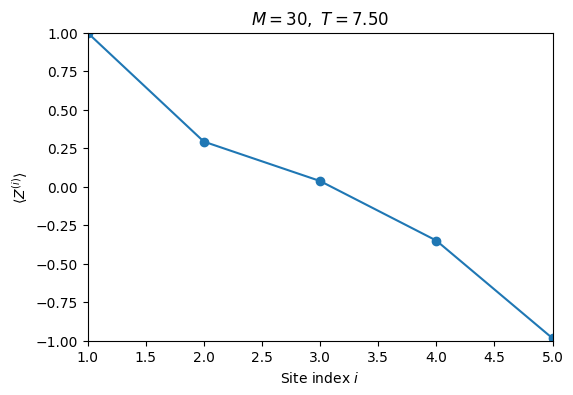

In [7]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
spin_profiles = np.load("Linblad_spin_profiles_eps_1_delta_ZZ_0.5_delta_t_0.25.npy")
Ms = list(range(0, 51))

n = 5
n_anc = 2
delta_t = 0.25
eps = 1
Delta_ZZ = 0.5
N = 1
from IPython.display import HTML
n=5
fig, ax = plt.subplots(figsize=(6, 4))
ax.set_xlim(1, n)
ax.set_ylim(-1, +1)
ax.set_xlabel("Site index $i$")
ax.set_ylabel(r"$\langle Z^{(i)}\rangle$")
line, = ax.plot([], [], marker="o", linestyle="-")

M = 31
spin_profiles_30 = spin_profiles[:M]
def init():
    line.set_data([], [])
    return (line,)

def update(frame):
    y = spin_profiles_30[frame]
    x = np.arange(1, n + 1)
    line.set_data(x, y)
    ax.set_title(f"$M={Ms[frame]},\\ T={Ms[frame]*delta_t:.2f}$")
    return (line,)

ani = FuncAnimation(
    fig,
    update,
    frames=len(Ms[:M]),
    init_func=init,
    blit=True,
    interval=200,   # ms between frames
)

HTML(ani.to_jshtml())
from matplotlib.animation import PillowWriter

ani.save("spin_evolution.gif", writer=PillowWriter(fps=5))